# 04 – A diagram as a story

`03_one_text_per_diagram.ipynb` showed that one text per diagram loses names in short labels. spaCy still sees the
name, but with the wrong type: "Tom - Burgerzaken" becomes an ORG, "Dossier Marleen Jacobs" a WORK_OF_ART. The likely
causes:

- every label is still its own one-line "sentence";
- its neighbours are other labels (lanes, departments), because the lines follow the XML order;
- a word at the start of a line reads like a proper noun.

This notebook tries to turn a diagram into a **story**: the elements in the order of the process, framed as sentences.
Ordering and framing are tested separately:

| Mode | Order | Framing | |
|---|---|---|---|
| per element | – | – | reference, notebook 02 |
| one text + element type | XML | "Taak: …" per line | reference, best one-text mode of notebook 03 |
| flow order | along the process flow | "Taak: …" per line | effect of the order alone |
| story | along the process flow | Dutch sentences | effect of order + framing |

All four run the same improvement steps (`improved.cumulative_steps()`, steps 0–11).

## Setup

In [1]:
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import experiment
import improved
import pii_eval

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.max_rows", 100)

files, elements, spans = pii_eval.load_corpus("data/synthetic")
STEPS = improved.cumulative_steps()
MODES = {
    "per element": {},
    "one text + element type": {"whole_document": True, "document_layout": "typed"},
    "flow order": {"whole_document": True, "document_layout": "flow"},
    "story": {"whole_document": True, "document_layout": "story"},
}
print(f"{len(files)} files, {len(elements)} text elements, {len(spans)} PII spans; {len(STEPS)} steps x {len(MODES)} modes")

20 files, 551 text elements, 205 PII spans; 12 steps x 4 modes


## From diagram to story

**Flow order** (`document_layout="flow"`): pools and lanes first; then, per process, the flow nodes depth-first from
the start event along the sequence flows. Each node is followed by its documentation, the text annotations attached to
it and its labelled outgoing flows ("Ja", "Nee"). Data objects, message flows and anything not reached come last.

**Story** (`document_layout="story"`): the same order, with each element framed as a sentence according to its type:
"Dit proces heet: …", "Betrokken in dit proces: …", "Stap 3: …", "Daarna volgt de beslissing: …",
"Bij antwoord Ja gaat het verder met stap 4.", "Toelichting: …", "Opmerking: …". The labels themselves are inserted
unchanged, so every detection maps back to its element exactly as before.

The same diagram in the three one-text layouts (step 11):

In [2]:
example = "fuifkwaliteitslabel-aalter.bpmn"
for mode in ["one text + element type", "flow order", "story"]:
    doc, segments = improved.bpmn_document(files[example], replace(STEPS["11 name parts"], **MODES[mode]))
    print(f"--- {mode}: {len(segments)} elements -> {len(doc)} characters")
    print("\n".join(doc.splitlines()[:18]), "\n")

--- one text + element type: 28 elements -> 977 characters
Pool: Jeugd - Fuifkwaliteitslabel aanvraag Aalter.
Documentatie: Aanvrager Nele Vandenberghe, wonende te Veldstraat 153, 3500 Hasselt, geboren op 19-08-1960, rijksregisternummer 600819 817 26.
Pool: Elke Van de Velde.
Bericht: Aanvraag.
Lane: Organisator.
Lane: Jeugddienst.
Lane: Schepencollege.
Lane: Financiële dienst.
Start: 1 maand voor de fuif.
Taak: Terugbetaling op BE32 5678 9073 9102.
Beslissing: Aanvraag volledig?
Taak: ADM.
Documentatie: Testdossier: INSZ 600819 817 26, adres Veldstraat 153, 3500 Hasselt.
Taak: Advies Financieel directeur.
Taak: Controle RRN 60121670958.
Taak: Binnen 30 dagen.
Einde: Label toegekend.
Einde: Aanvraag geweigerd. 

--- flow order: 28 elements -> 977 characters
Pool: Jeugd - Fuifkwaliteitslabel aanvraag Aalter.
Documentatie: Aanvrager Nele Vandenberghe, wonende te Veldstraat 153, 3500 Hasselt, geboren op 19-08-1960, rijksregisternummer 600819 817 26.
Pool: Elke Van de Velde.
Lane: Organisa

## Run all steps in all modes

In [3]:
runs = {}  # (mode, step) -> experiment.StepResult
for mode, switches in MODES.items():
    for name, cfg in STEPS.items():
        runs[mode, name] = experiment.run_step(replace(cfg, **switches), files, spans)
rows = pd.DataFrame([{"mode": mode, "step": name, **r.row} for (mode, name), r in runs.items()])
print(len(runs), "runs")

48 runs


Check: the two reference modes give the same numbers as notebooks 02 and 03 (if their results exist).

In [4]:
checked = ["precision", "recall", "recall_full", "recall_typed", "residual_pii"]
references = {
    "per element": ("results/improvements.csv", None),
    "one text + element type": ("results/one_text.csv", "one text + element type"),
}
for mode, (csv, csv_mode) in references.items():
    if not Path(csv).exists():
        print(f"{csv} not found; run the earlier notebook first")
        continue
    ref = pd.read_csv(csv).query("group == 'overall'")
    if csv_mode:
        ref = ref[ref["mode"] == csv_mode]
    ref = ref.set_index("approach")
    ours = rows[rows["mode"] == mode].set_index("step")
    pd.testing.assert_frame_equal(ours.loc[ref.index, checked], ref[checked], check_names=False)
    print(f"{mode} == {csv} for {len(ref)} steps")

per element == results/improvements.csv for 12 steps
one text + element type == results/one_text.csv for 12 steps


## Comparison per step

In [5]:
METRICS = {
    "precision": "precision",
    "recall_full": "PII fully covered",
    "residual_pii": "PII left after anonymizing",
    "review_false_positives": "review items that are not PII",
}
table = rows.pivot(index="step", columns="mode", values=list(METRICS)).loc[list(STEPS)]
table = table.reindex(columns=pd.MultiIndex.from_product([list(METRICS), list(MODES)]))
table.round(3)

precision                                     \
                              per element one text + element type flow order   
step                                                                           
0 baseline                          0.622                   0.602      0.602   
1 entity filter                     0.623                   0.600      0.600   
2 thresholds                        0.655                   0.634      0.634   
3 allow-list                        0.727                   0.687      0.687   
4 RRN checksum                      0.727                   0.687      0.687   
5 acronym gate                      0.727                   0.687      0.687   
6 dedup                             0.727                   0.687      0.687   
7 documentation + annotations       0.801                   0.774      0.774   
8 Belgian recognizers               0.837                   0.812      0.812   
9 no LOCATION                       0.954                   0.981      0.981   
10 name particles                   0.953                   0.980      0.980   
11 name parts                       0.953                   0.980      0.980   

                                     recall_full                          \
                               story per element one text + element type   
step                                                                       
0 baseline                     0.583       0.385                   0.376   
1 entity filter                0.571       0.346                   0.332   
2 thresholds                   0.607       0.405                   0.390   
3 allow-list                   0.662       0.405                   0.390   
4 RRN checksum                 0.662       0.410                   0.395   
5 acronym gate                 0.662       0.410                   0.395   
6 dedup                        0.662       0.410                   0.395   
7 documentation + annotations  0.759       0.727                   0.712   
8 Belgian recognizers          0.798       0.941                   0.927   
9 no LOCATION                  0.962       0.941                   0.927   
10 name particles              0.961       0.976                   0.956   
11 name parts                  0.961       0.976                   0.956   

                                                residual_pii  \
                              flow order  story  per element   
step                                                           
0 baseline                         0.376  0.371        0.600   
1 entity filter                    0.332  0.327        0.644   
2 thresholds                       0.390  0.385        0.585   
3 allow-list                       0.390  0.385        0.585   
4 RRN checksum                     0.395  0.390        0.585   
5 acronym gate                     0.395  0.390        0.585   
6 dedup                            0.395  0.390        0.585   
7 documentation + annotations      0.712  0.707        0.254   
8 Belgian recognizers              0.927  0.922        0.029   
9 no LOCATION                      0.927  0.922        0.029   
10 name particles                  0.956  0.951        0.024   
11 name parts                      0.956  0.951        0.015   

                                                                         \
                              one text + element type flow order  story   
step                                                                      
0 baseline                                      0.615      0.615  0.620   
1 entity filter                                 0.663      0.663  0.668   
2 thresholds                                    0.605      0.605  0.610   
3 allow-list                                    0.605      0.605  0.610   
4 RRN checksum                                  0.605      0.605  0.610   
5 acronym gate                                  0.605      0.605  0.610   
6 dedup                                         0.605 

Difference with per element (positive = higher than per element):

In [6]:
diff = pd.concat(
    {metric: table[metric].drop(columns="per element").sub(table[metric]["per element"], axis=0) for metric in METRICS},
    axis=1,
)
diff.round(3)

precision                    \
                              one text + element type flow order  story   
step                                                                      
0 baseline                                     -0.020     -0.020 -0.039   
1 entity filter                                -0.023     -0.023 -0.052   
2 thresholds                                   -0.021     -0.021 -0.048   
3 allow-list                                   -0.040     -0.040 -0.065   
4 RRN checksum                                 -0.040     -0.040 -0.065   
5 acronym gate                                 -0.040     -0.040 -0.065   
6 dedup                                        -0.040     -0.040 -0.065   
7 documentation + annotations                  -0.027     -0.027 -0.042   
8 Belgian recognizers                          -0.025     -0.025 -0.039   
9 no LOCATION                                   0.027      0.027  0.008   
10 name particles                               0.027      0.027  0.008   
11 name parts                                   0.027      0.027  0.008   

                                          recall_full                    \
                              one text + element type flow order  story   
step                                                                      
0 baseline                                     -0.009     -0.009 -0.014   
1 entity filter                                -0.014     -0.014 -0.019   
2 thresholds                                   -0.015     -0.015 -0.020   
3 allow-list                                   -0.015     -0.015 -0.020   
4 RRN checksum                                 -0.015     -0.015 -0.020   
5 acronym gate                                 -0.015     -0.015 -0.020   
6 dedup                                        -0.015     -0.015 -0.020   
7 documentation + annotations                  -0.015     -0.015 -0.020   
8 Belgian recognizers                          -0.014     -0.014 -0.019   
9 no LOCATION                                  -0.014     -0.014 -0.019   
10 name particles                              -0.020     -0.020 -0.025   
11 name parts                                  -0.020     -0.020 -0.025   

                                         residual_pii                    \
                              one text + element type flow order  story   
step                                                                      
0 baseline                                      0.015      0.015  0.020   
1 entity filter                                 0.019      0.019  0.024   
2 thresholds                                    0.020      0.020  0.025   
3 allow-list                                    0.020      0.020  0.025   
4 RRN checksum                                  0.020      0.020  0.025   
5 acronym gate                                  0.020      0.020  0.025   
6 dedup                                         0.020      0.020  0.020   
7 documentation + annotations                   0.019      0.019  0.019   
8 Belgian recognizers                           0.020      0.020  0.020   
9 no LOCATION                                   0.020      0.020  0.020   
10 name particles                               0.020      0.020  0.020   
11 name parts                                   0.009      0.009  0.009   

                               review_false_positives                   
                              one text + element type flow order story  
step                                                                    
0 baseline                                        4.0        4.0   8.0  
1 entity filter                                   3.0        3.0   8.0  
2 thresholds                                      3.0        3.0   8.0  
3 allow-list                                      6.0        6.0  10.0  
4 RRN checksum                                    6.0        6.0  10.0  
5 acronym gate                                    6.0        6.0  10.0  
6 dedup  

Cost of detection: analyzer calls and detection time for all 20 diagrams (models already loaded):

In [7]:
cost = rows.pivot(index="step", columns="mode", values=["analyze_calls", "detect_seconds"]).loc[list(STEPS)]
cost.reindex(columns=pd.MultiIndex.from_product([["analyze_calls", "detect_seconds"], list(MODES)]))

analyze_calls                          \
                                per element one text + element type   
step                                                                  
0 baseline                            437.0                    20.0   
1 entity filter                       437.0                    20.0   
2 thresholds                          437.0                    20.0   
3 allow-list                          437.0                    20.0   
4 RRN checksum                        437.0                    20.0   
5 acronym gate                        437.0                    20.0   
6 dedup                               437.0                    20.0   
7 documentation + annotations         551.0                    20.0   
8 Belgian recognizers                 551.0                    20.0   
9 no LOCATION                         551.0                    20.0   
10 name particles                     551.0                    20.0   
11 name parts                         551.0                    20.0   

                                               detect_seconds  \
                              flow order story    per element   
step                                                            
0 baseline                          20.0  20.0           3.31   
1 entity filter                     20.0  20.0           6.20   
2 thresholds                        20.0  20.0           2.31   
3 allow-list                        20.0  20.0           2.51   
4 RRN checksum                      20.0  20.0           1.76   
5 acronym gate                      20.0  20.0           1.65   
6 dedup                             20.0  20.0           1.24   
7 documentation + annotations       20.0  20.0           2.34   
8 Belgian recognizers               20.0  20.0           1.87   
9 no LOCATION                       20.0  20.0           2.35   
10 name particles                   20.0  20.0           1.96   
11 name parts                       20.0  20.0           2.01   

                                                                        
                              one text + element type flow order story  
step                                                                    
0 baseline                                       0.43       0.52  0.54  
1 entity filter                                  0.38       0.47  0.52  
2 thresholds                                     0.40       0.43  0.57  
3 allow-list                                     0.37       0.41  0.49  
4 RRN checksum                                   0.38       0.44  0.49  
5 acronym gate                                   0.38       0.41  0.54  
6 dedup                                          0.41       0.42  0.52  
7 documentation + annotations                    0.69       0.59  0.68  
8 Belgian recognizers                            0.70       0.58  0.68  
9 no LOCATION                                    0.68       0.65  0.64  
10 name particles                                0.59       0.54  0.62  
11 name parts                                    0.61       0.57  0.66

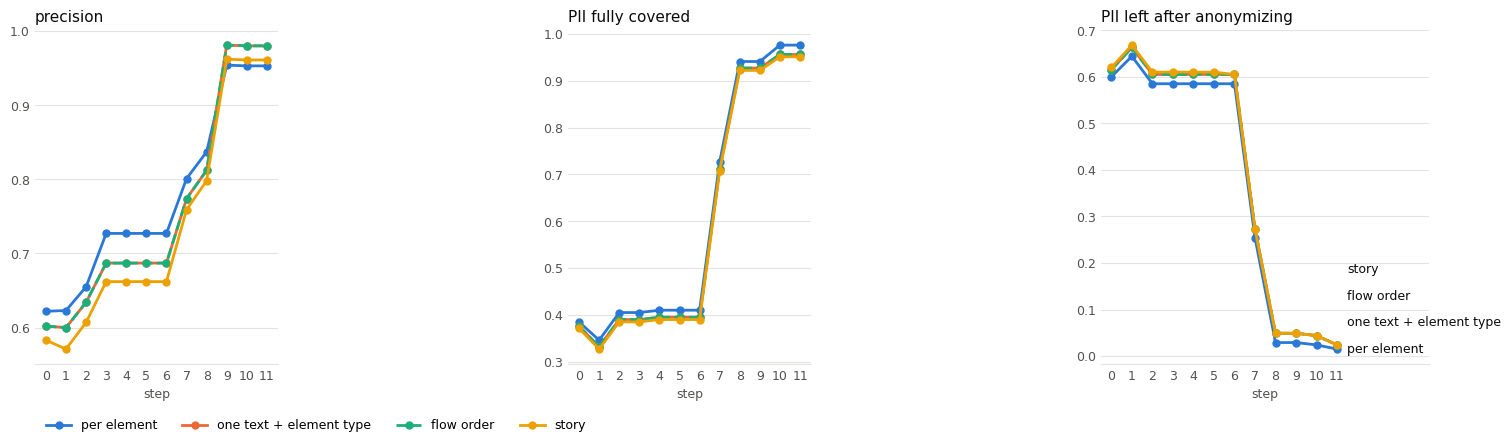

In [8]:
# Categorical slots 1-4 of the reference palette, one per mode; values are also in the tables above
COLORS = dict(zip(MODES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
PANELS = ["precision", "recall_full", "residual_pii"]

x = range(len(STEPS))
short = [name.split(" ", 1)[0] for name in STEPS]
# each panel has its own y-range (the differences are a few points); the last one is wider for the labels
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1, 1, 1.35]})
for ax, metric in zip(axes, PANELS):
    for mode, color in COLORS.items():
        # flow order coincides with "one text + element type": dashed, so both stay visible
        style = "--" if mode == "flow order" else "-"
        ax.plot(x, table[metric][mode], color=color, linewidth=2, linestyle=style, marker="o", markersize=5, label=mode)
    ax.set_title(METRICS[metric], loc="left", fontsize=11, color=INK)
    ax.set_xticks(list(x), short)
    ax.set_xlabel("step", color=MUTED, fontsize=9)
    ax.tick_params(colors=MUTED, labelsize=9, length=0)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)

# direct labels at the line ends of the last panel, nudged apart when the values are close
ax, metric = axes[-1], PANELS[-1]
low, high = ax.get_ylim()
label_y, prev = {}, low - 1
for mode in sorted(MODES, key=lambda m: table[metric][m].iloc[-1]):
    prev = label_y[mode] = max(table[metric][mode].iloc[-1], prev + 0.08 * (high - low))
for mode in MODES:
    ax.annotate(mode, (len(STEPS) - 1, table[metric][mode].iloc[-1]), xytext=(len(STEPS) - 0.5, label_y[mode]),
                textcoords="data", va="center", fontsize=9, color=INK)
ax.set_xlim(-0.5, len(STEPS) + 3.5)
axes[0].legend(loc="upper left", frameon=False, fontsize=9, ncol=4, bbox_to_anchor=(0, -0.13))
fig.tight_layout()
plt.show()

## Why labels win or lose

The four labels from the analysis in notebook 03. For each mode: what spaCy (the model Presidio uses) makes of the
label, inside the text of that mode at step 11. Only PERSON counts as a name in the pipeline.

In [9]:
spacy_nl = improved.spacy_model("nl")  # the spaCy model inside Presidio's NLP engine
labels = {
    "melding-openbaar-domein-hasselt.bpmn": "Tom - Burgerzaken",
    "aanvraag-rijbewijs-tienen.bpmn": "Contact Marleen (+32493276528)",
    "subsidie-vereniging-aalst.bpmn": "Dossier Marleen Jacobs (°04/03/1996)",
    "huwelijk-genk.bpmn": "Doorsturen naar Lander Yilmaz",
}
found = {}
for f, label in labels.items():
    for mode, switches in MODES.items():
        if mode == "per element":
            text, start = label, 0
        else:
            text, _ = improved.bpmn_document(files[f], replace(STEPS["11 name parts"], **switches))
            start = text.index(label)
        doc = spacy_nl(text)
        ents = [f"{e.text} → {e.label_}" for e in doc.ents if start <= e.start_char and e.end_char <= start + len(label)]
        found[label, mode] = "; ".join(ents) or "–"
pd.Series(found).unstack()[list(MODES)]

,per element,one text + element type,flow order,story
Contact Marleen (+32493276528),Marleen → PERSON; +32493276528 → DATE,Contact Marleen → WORK_OF_ART; +32493276528 → DATE,Contact Marleen → WORK_OF_ART; +32493276528 → DATE,Contact Marleen → WORK_OF_ART; +32493276528 → DATE
Doorsturen naar Lander Yilmaz,–,Yilmaz → PERSON,Yilmaz → PERSON,Yilmaz → PERSON
Dossier Marleen Jacobs (°04/03/1996),Marleen Jacobs → PERSON; 04/03/1996 → DATE,Dossier Marleen Jacobs → WORK_OF_ART,Dossier Marleen Jacobs → WORK_OF_ART,Dossier Marleen Jacobs → WORK_OF_ART
Tom - Burgerzaken,Tom - Burgerzaken → PERSON,Tom - Burgerzaken → WORK_OF_ART,Tom - Burgerzaken → WORK_OF_ART,Tom - Burgerzaken → WORK_OF_ART


In [10]:
# the lines around one of them, in the story
text, _ = improved.bpmn_document(files["melding-openbaar-domein-hasselt.bpmn"], replace(STEPS["11 name parts"], **MODES["story"]))
lines = text.splitlines()
i = next(n for n, line in enumerate(lines) if "Tom - Burgerzaken" in line)
print("\n".join(lines[max(0, i - 4) : i + 4]))

Dit proces heet: Melding schade openbaar domein Hasselt.
Externe partij: Melder.
Betrokken in dit proces: Melder.
Betrokken in dit proces: Tom Lemmens.
Betrokken in dit proces: Tom - Burgerzaken.
Het proces begint met: Melding via app of telefoon.
Stap 1: Contact Inge (+32 11 93 64 26).
Opmerking: Navragen bij Ruben.


Even directly after "Betrokken in dit proces: Tom Lemmens." — the same person, framed the same way — spaCy labels "Tom - Burgerzaken" as WORK_OF_ART. The line before is outside the few words the model looks at.

## What flow order and story change at step 11, compared with per element

In [11]:
last = list(STEPS)[-1]
per_element = runs["per element", last]
for mode in ["flow order", "story"]:
    r = runs[mode, last]
    d = pii_eval.diff_steps((per_element.spans, per_element.detections), (r.spans, r.detections))
    print(f"=== {mode} vs per element: {r.row['crossing_boundary']} detection(s) crossing an element boundary")
    for title in ["fp_removed", "fp_added", "pii_lost", "pii_gained"]:
        print(f"\n--- {title}: {len(d[title])}")
        if len(d[title]):
            display(d[title])

=== flow order vs per element: 0 detection(s) crossing an element boundary

--- fp_removed: 7


,location,entity,match
1,name,PERSON,Plaatsbezoek
2,documentation,PERSON,Opgelet
3,name,PERSON,Plaatsbezoek
7,name,PERSON,Adviezen
8,name,PERSON,Adviezen
9,name,PERSON,Adviezen
10,documentation,PERSON,Opgelet



--- fp_added: 1


,location,entity,match
1,name,PERSON,Evenementenloket



--- pii_lost: 4


...

,location,entity,match
0,name,PERSON,Plaatsbezoek
2,name,PERSON,Plaatsbezoek
4,name,PERSON,Evenementenloket
7,name,PERSON,Mercurius



--- pii_lost: 5


,file,location,entity,value,text
6,aanvraag-rijbewijs-sintniklaas.bpmn,name,PERSON,Marleen Van de Velde,Dossier Marleen Van de Velde (°6 juni 1998)
24,omgevingsvergunning-poperinge.bpmn,name,PERSON,Elke Desmet,Elke Desmet
55,subsidie-vereniging-aalst.bpmn,name,PERSON,Marleen Jacobs,Dossier Marleen Jacobs (°04/03/1996)
93,aanvraag-rijbewijs-tienen.bpmn,name,PERSON,Marleen,Contact Marleen (+32493276528)
191,melding-openbaar-domein-hasselt.bpmn,name,PERSON,Tom,Tom - Burgerzaken



--- pii_gained: 1


,file,location,entity,value,text
141,huwelijk-genk.bpmn,name,PERSON,Lander Yilmaz,Doorsturen naar Lander Yilmaz


False positives per entity type at step 11:

In [12]:
pd.DataFrame({
    mode: runs[mode, last].detections.loc[lambda d: ~d.tp].entity.value_counts() for mode in MODES
}).fillna(0).astype(int)

,per element,one text + element type,flow order,story
entity,,,,
PERSON,10,4,4,8


In [13]:
out = pd.concat([r.summary.assign(mode=mode) for (mode, name), r in runs.items()])
out = out[["mode", *experiment.SUMMARY_COLUMNS]]
Path("results").mkdir(exist_ok=True)
out.to_csv("results/story.csv", index=False)
print(f"{len(out)} rows -> results/story.csv")

624 rows -> results/story.csv


## Conclusions

**Flow order changes nothing.** In every step, ordering the lines along the process gives exactly the same result as
the XML order. spaCy's NER only looks a few words to the left and right of each token, so which line comes before or
after a label hardly matters, and a short label is still its own sentence.

**Framing as a story makes things slightly worse.** At step 11 the story has a precision of 0.961 (typed lines: 0.980,
per element: 0.953) and covers 95.1% of the PII fully (typed lines: 95.6%, per element: 97.6%). The frame words do
become the local context of each label, and not in a good way: after "Stap 3:" a capitalized word such as
"Plaatsbezoek" or "Mercurius" is taken for a name more often (8 PERSON false positives instead of 4).

**The four problem labels keep the wrong type in every one-text mode.** "Tom - Burgerzaken" and
"Dossier Marleen Jacobs" stay WORK_OF_ART, also inside the story. The cause is the model, not the order or the
framing: `nl_core_news_md` is trained on news text with a small context window. It does not "read" a diagram as a
whole, however it is written down.

**Cost:** the story is longer text (≈30% more characters), so detection is about twice as slow as the typed lines,
still faster than per element and with the same 20 analyzer calls.

**What this means for a "story" of a BPMN**
- With spaCy-based Presidio, a story is **not worth it**. One text per diagram with typed lines (notebook 03) remains
  the better one-text option, and per element remains the best for recall.
- A story becomes interesting for a detector that **does** read the whole document: a transformer NER model with a
  long context, or an LLM behind a detection endpoint. For such a model "Stap 2: Tom - Burgerzaken, in de lane
  Burgerzaken" is clearly a person, and `improved.bpmn_document(..., document_layout="story")` already produces that
  text with offsets that map back to the elements. That would be the next experiment for this idea.